# Verified Bell pairs on three processor models: routing, noise, and one parity-check protection strategy

**UCF IBM Qiskit Fall Fest 2026, Geometry-aware quantum cloud challenge (quanTA, University of Saskatchewan)**
**Author: Muntaser Syed**

This notebook prepares the target Bell state $|\Phi^+\rangle = (|00\rangle + |11\rangle)/\sqrt{2}$ at the two designated ports of each of the three processor models in the challenge prompt, and completes the full $3 \times 3$ comparison: ideal baseline, noisy baseline, and noisy plus one protection strategy, for each model (Cases 1-9).

**The one protection strategy** is a single $ZZ$ parity check: after the Bell pair has been delivered to the ports, one ancilla qubit (starting in $|0\rangle$) receives a CX from each port. The ancilla ends in $|0\rangle$ for even parity and $|1\rangle$ for odd parity. Shots (equivalently, density-matrix weight) with ancilla outcome $1$ are discarded. The ancilla for each model is chosen by a fixed, outcome-blind rule stated in Section 5, not by which ancilla gives the best fidelity.

**Headline findings** (exact density-matrix values, Section 6):

- Noisy baseline fidelity is ordered by routed circuit cost, not by processor size: 0.915 (2016-inspired, 7 CX) > 0.852 (hyperbolic-inspired, 13 CX) > 0.795 (contemporary IBM-style, 19 CX). The 13-qubit hyperbolic model beats the 9-qubit contemporary model because its ports are closer on the graph (3 hops vs 4 hops).
- The parity check helps only where it costs no SWAPs. On the 2016-inspired model the ancilla is adjacent to both ports, the check costs exactly 2 extra CX, and conditional fidelity rises from 0.915 to 0.941 at a 91.7% acceptance fraction.
- Where the check itself must be routed, it does not pay: conditional fidelity falls to 0.769 (contemporary, from 0.795) and 0.847 (hyperbolic, from 0.852), while 15.2% and 10.8% of shots are discarded. The check segment adds 14 and 8 CX respectively, and noise injected by those gates is largely after, or invisible to, the parity measurement.
- Recommendation (Section 9): give each designated port pair a dedicated parity-check ancilla coupled directly to both ports, so a parity check costs 2 CX and 0 SWAPs. That geometry is the only one in this benchmark where protection produced a net gain.

## 1. Task definition and assumptions

All definitions follow the challenge prompt deck and the starter notebook `ideal_and_noisy_example.ipynb` supplied in the Hackathon Prompt Resources zip (re-downloaded 2026-11-17; the zip governs where it differs from any summary).

- **Processor models and ports.** 2016-inspired reference: 5 qubits, ports (0, 4). Contemporary IBM-style: 9 qubits, ports (0, 7). Hyperbolic-inspired model: 13 qubits, ports (0, 12). Coupling graphs, qubit positions, and port pairs are copied verbatim from the starter notebook; the prompt diagrams carry no qubit numbers, so the starter notebook's position-based numbering is used.
- **Gate set.** `h` and `cx` only (plus `sdg` for $YY$ measurement rotations in the shot-based cross-check). Every drawn coupling link allows CX in both directions.
- **Compilation.** Identical to the starter notebook: place the logical qubits on the ports, route with Qiskit's `basic` router at `optimization_level=0`, then apply the routing SWAPs in reverse order so the Bell pair ends on the designated ports, and expand each SWAP into 3 CX gates.
- **Noise model (common benchmark).** A two-qubit depolarizing channel of strength 0.02 applied after every CX, including the CX gates that implement SWAPs. H gates are ideal. No readout error, relaxation, or single-qubit noise is included. This is exactly the starter notebook's synthetic model.
- **Fidelity.** $F(\Phi^+) = [1 + \langle XX\rangle - \langle YY\rangle + \langle ZZ\rangle]/4$, evaluated on the reduced state of the two ports. Headline values are computed exactly from density matrices (Aer `density_matrix` method), so they carry no sampling error; Section 7 repeats the measurement with finite shots to attach the uncertainty a shot-based experiment would report.
- **Cost reporting.** For every case: circuit depth, number of two-qubit (CX) gates, SWAP overhead (SWAPs before expansion into CX, counted outbound plus return), physical qubits actually used including the ancilla, and, for protected cases, the postselection acceptance fraction and discarded fraction.
- **Software.** Qiskit 2.6.2, Qiskit Aer 0.18.2, Python 3.12. All random seeds are fixed where sampling is used.

In [1]:
import math
from collections import deque

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Pauli, Statevector, partial_trace
from qiskit.transpiler import CouplingMap
import qiskit, qiskit_aer
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error

print("qiskit", qiskit.__version__, "| qiskit-aer", qiskit_aer.__version__)

CX_NOISE = 0.02  # two-qubit depolarizing strength after each CX (starter notebook value)

qiskit 2.6.2 | qiskit-aer 0.18.2


## 2. The three coupling graphs

Definitions copied from the starter notebook. Red rings mark the designated output ports. The gold diamond marks the protection ancilla selected in Section 5 (shown here for orientation; the selection rule and scan are in Section 5).

In [2]:
models = {
    "2016-inspired reference": {
        "ports": (0, 4),
        "positions": [(0, 2), (-1.55, 0.75), (1.55, 0.75), (0, -0.45), (0, -2)],
        "edges": [(0, 1), (0, 2), (0, 3), (3, 4)],
        "color": "#2151c7",
    },
    "Contemporary IBM-style": {
        "ports": (0, 7),
        "positions": [
            (-2.1, 1), (-0.9, 1.7), (0.3, 1), (1.5, 1.7),
            (-1.5, -0.35), (-0.3, 0.35), (0.9, -0.35), (2.1, 0.35), (-0.3, -1.65),
        ],
        "edges": [
            (0, 1), (0, 4), (1, 2), (1, 5), (2, 3), (2, 5), (2, 6),
            (3, 7), (4, 5), (5, 6), (5, 8), (6, 7),
        ],
        "color": "#137665",
    },
    "Hyperbolic-inspired model": {
        "ports": (0, 12),
        "positions": [
            (0, 2.08), (-2, 1.14), (0, 1.14), (2, 1.14),
            (-1, 0.59), (1, 0.59), (0, 0), (-1, -0.59), (1, -0.59),
            (-2, -1.14), (0, -1.14), (2, -1.14), (0, -2.08),
        ],
        "edges": [
            (0, 1), (0, 3), (1, 9), (3, 11), (9, 12), (11, 12),
            (2, 4), (2, 5), (4, 7), (5, 8), (7, 10), (8, 10),
            (0, 2), (1, 4), (3, 5), (7, 9), (8, 11), (10, 12),
            (2, 6), (4, 6), (5, 6), (6, 7), (6, 8), (6, 10),
        ],
        "color": "#7139cc",
    },
}
for m in models.values():
    m["n"] = len(m["positions"])

def graph_distances(edges, src):
    adj = {}
    for a, b in edges:
        adj.setdefault(a, []).append(b)
        adj.setdefault(b, []).append(a)
    dist = {src: 0}
    dq = deque([src])
    while dq:
        u = dq.popleft()
        for v in adj[u]:
            if v not in dist:
                dist[v] = dist[u] + 1
                dq.append(v)
    return dist

for name, m in models.items():
    d = graph_distances(m["edges"], m["ports"][0])
    print(f"{name}: {m['n']} qubits, {len(m['edges'])} links, ports {m['ports']}, "
          f"port-to-port graph distance {d[m['ports'][1]]} hops")

2016-inspired reference: 5 qubits, 4 links, ports (0, 4), port-to-port graph distance 2 hops
Contemporary IBM-style: 9 qubits, 12 links, ports (0, 7), port-to-port graph distance 4 hops
Hyperbolic-inspired model: 13 qubits, 24 links, ports (0, 12), port-to-port graph distance 3 hops


## 3. Compilation: Bell pair delivered to the ports

The compilation helper below is the starter notebook's method, generalized to any logical circuit: route at the chosen layout with the `basic` router, record the inserted SWAPs, append them in reverse order so every logical qubit returns to its assigned physical qubit, then decompose SWAPs into CX gates with the wire order fixed. A routed CX count therefore satisfies CX $= 1 + 6s$ for the Bell circuit, where $s$ is the number of outbound SWAPs (each SWAP appears outbound and on return, and costs 3 CX).

In [3]:
def compile_at_layout(logical, edges, layout):
    """Route `logical` with logical qubit i placed on physical qubit layout[i],
    then undo the routing SWAPs so all logical qubits end at their layout qubits.
    Returns (compiled circuit on the full register, number of outbound SWAPs)."""
    coupling = CouplingMap(edges)
    coupling.make_symmetric()
    routed = transpile(
        logical, coupling_map=coupling, initial_layout=list(layout),
        routing_method="basic", basis_gates=["h", "cx", "swap", "sdg"],
        optimization_level=0,
    )
    swaps = [
        tuple(routed.find_bit(q).index for q in ins.qubits)
        for ins in routed.data if ins.operation.name == "swap"
    ]
    at_layout = QuantumCircuit(routed.num_qubits)
    at_layout.compose(routed, inplace=True)
    for a, b in reversed(swaps):
        at_layout.swap(a, b)
    compiled = transpile(
        at_layout, coupling_map=coupling,
        initial_layout=list(range(at_layout.num_qubits)),
        routing_method="none", basis_gates=["h", "cx", "sdg"],
        optimization_level=0,
    )
    return compiled, len(swaps)

def active_qubits(circuit):
    return sorted({circuit.find_bit(q).index for ins in circuit.data for q in ins.qubits})

bell = QuantumCircuit(2)
bell.h(0)
bell.cx(0, 1)

unprotected = {}
for name, m in models.items():
    circ, s = compile_at_layout(bell, m["edges"], m["ports"])
    used = {tuple(sorted(circ.find_bit(q).index for q in ins.qubits))
            for ins in circ.data if len(ins.qubits) == 2}
    assert used <= {tuple(sorted(e)) for e in m["edges"]}, f"{name}: CX off the coupling graph"
    unprotected[name] = {"circuit": circ, "swaps_out": s}
    print(f"{name}: outbound SWAPs {s} (total {2*s} with return), "
          f"CX {circ.count_ops()['cx']}, depth {circ.depth()}, "
          f"physical qubits used {len(active_qubits(circ))} of {m['n']}")

2016-inspired reference: outbound SWAPs 1 (total 2 with return), CX 7, depth 8, physical qubits used 3 of 5
Contemporary IBM-style: outbound SWAPs 3 (total 6 with return), CX 19, depth 20, physical qubits used 5 of 9
Hyperbolic-inspired model: outbound SWAPs 2 (total 4 with return), CX 13, depth 14, physical qubits used 4 of 13


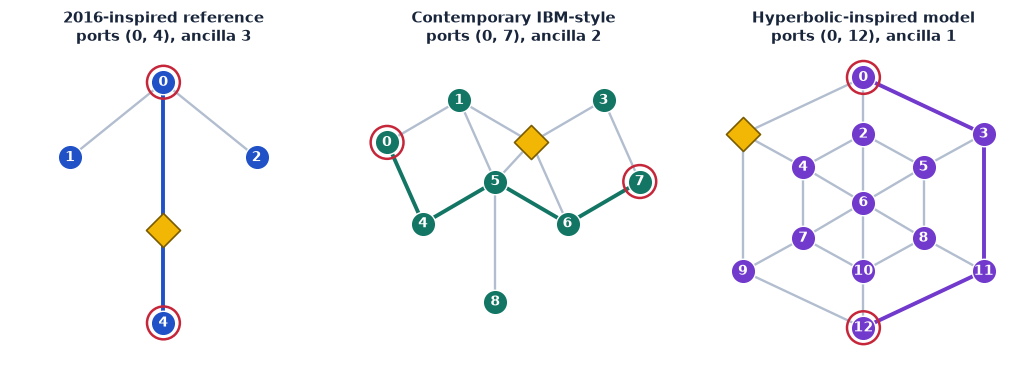

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.55), layout="constrained", facecolor="white")
ANCILLA_PREVIEW = {"2016-inspired reference": 3, "Contemporary IBM-style": 2, "Hyperbolic-inspired model": 1}
for (name, m), ax in zip(models.items(), axes):
    pos, color = m["positions"], m["color"]
    used_edges = {tuple(sorted(unprotected[name]["circuit"].find_bit(q).index for q in ins.qubits))
                  for ins in unprotected[name]["circuit"].data if len(ins.qubits) == 2}
    for a, b in m["edges"]:
        x0, y0 = pos[a]; x1, y1 = pos[b]
        used = tuple(sorted((a, b))) in used_edges
        ax.plot([x0, x1], [y0, y1], color=color if used else "#b2becf",
                linewidth=2.8 if used else 1.7, zorder=1)
    ax.scatter(*zip(*pos), s=310, color=color, edgecolors="white", zorder=3)
    pp = [pos[q] for q in m["ports"]]
    ax.scatter(*zip(*pp), s=560, facecolors="none", edgecolors="#c62639", linewidths=1.8, zorder=2)
    ax.scatter(*pos[ANCILLA_PREVIEW[name]], s=300, marker="D", facecolors="#f2b705",
               edgecolors="#7a5b00", linewidths=1.2, zorder=5)
    for q, (x, y) in enumerate(pos):
        ax.text(x, y, str(q), ha="center", va="center", color="white", fontsize=10, weight="bold", zorder=4)
    ax.set_title(f"{name}\nports {m['ports']}, ancilla {ANCILLA_PREVIEW[name]}", fontsize=11, weight="bold", color="#18253b")
    ax.set(xlim=(-2.55, 2.55), ylim=(-2.55, 2.55), aspect="equal")
    ax.axis("off")
plt.show()

In [5]:
for name, r in unprotected.items():
    p = models[name]["ports"]
    display(Markdown(f"**{name}, unprotected circuit at ports {p[0]} and {p[1]}** (idle wires hidden)"))
    print(r["circuit"].draw(output="text", idle_wires=False, fold=-1))

**2016-inspired reference, unprotected circuit at ports 0 and 4** (idle wires hidden)

         ┌───┐     ┌───┐               ┌───┐     
q_0 -> 0 ┤ H ├──■──┤ X ├──■─────────■──┤ X ├──■──
         └───┘┌─┴─┐└─┬─┘┌─┴─┐     ┌─┴─┐└─┬─┘┌─┴─┐
q_3 -> 3 ─────┤ X ├──■──┤ X ├──■──┤ X ├──■──┤ X ├
              └───┘     └───┘┌─┴─┐└───┘     └───┘
q_4 -> 4 ────────────────────┤ X ├───────────────
                             └───┘               


**Contemporary IBM-style, unprotected circuit at ports 0 and 7** (idle wires hidden)

         ┌───┐     ┌───┐                                                                           ┌───┐     
q_0 -> 0 ┤ H ├──■──┤ X ├──■─────────────────────────────────────────────────────────────────────■──┤ X ├──■──
         └───┘┌─┴─┐└─┬─┘┌─┴─┐     ┌───┐                                             ┌───┐     ┌─┴─┐└─┬─┘┌─┴─┐
q_4 -> 4 ─────┤ X ├──■──┤ X ├──■──┤ X ├──■───────────────────────────────────────■──┤ X ├──■──┤ X ├──■──┤ X ├
              └───┘     └───┘┌─┴─┐└─┬─┘┌─┴─┐     ┌───┐               ┌───┐     ┌─┴─┐└─┬─┘┌─┴─┐└───┘     └───┘
q_5 -> 5 ────────────────────┤ X ├──■──┤ X ├──■──┤ X ├──■─────────■──┤ X ├──■──┤ X ├──■──┤ X ├───────────────
                             └───┘     └───┘┌─┴─┐└─┬─┘┌─┴─┐     ┌─┴─┐└─┬─┘┌─┴─┐└───┘     └───┘               
q_6 -> 6 ───────────────────────────────────┤ X ├──■──┤ X ├──■──┤ X ├──■──┤ X ├──────────────────────────────
                                            └───┘     └───┘┌─┴─┐└───┘     └───┘                              
q_7 -> 7 ─

**Hyperbolic-inspired model, unprotected circuit at ports 0 and 12** (idle wires hidden)

           ┌───┐     ┌───┐                                             ┌───┐     
  q_0 -> 0 ┤ H ├──■──┤ X ├──■───────────────────────────────────────■──┤ X ├──■──
           └───┘┌─┴─┐└─┬─┘┌─┴─┐     ┌───┐               ┌───┐     ┌─┴─┐└─┬─┘┌─┴─┐
  q_3 -> 3 ─────┤ X ├──■──┤ X ├──■──┤ X ├──■─────────■──┤ X ├──■──┤ X ├──■──┤ X ├
                └───┘     └───┘┌─┴─┐└─┬─┘┌─┴─┐     ┌─┴─┐└─┬─┘┌─┴─┐└───┘     └───┘
q_11 -> 11 ────────────────────┤ X ├──■──┤ X ├──■──┤ X ├──■──┤ X ├───────────────
                               └───┘     └───┘┌─┴─┐└───┘     └───┘               
q_12 -> 12 ───────────────────────────────────┤ X ├──────────────────────────────
                                              └───┘                              


## 4. Ideal and noisy baselines (Cases 1, 2, 4, 5, 7, 8)

The same compiled circuits are evaluated twice: exactly with a statevector (ideal) and with Aer density-matrix simulation under the common noise model. The fidelity is computed from the reduced density matrix of the two ports. Ideal fidelity is asserted to be 1 for every model, which verifies that the routing and return SWAPs deliver a genuine $|\Phi^+\rangle$ to the ports, so all noisy-case loss is attributable to the noise channel acting on the routed gates.

In [6]:
noise_model = NoiseModel()
noise_model.add_all_qubit_quantum_error(depolarizing_error(CX_NOISE, 2), ["cx"])
noisy_sim = AerSimulator(method="density_matrix", noise_model=noise_model)
ideal_sim = AerSimulator(method="density_matrix")

def port_fidelity_from_dm(dm):
    xx = dm.expectation_value(Pauli("XX")).real
    yy = dm.expectation_value(Pauli("YY")).real
    zz = dm.expectation_value(Pauli("ZZ")).real
    return (xx, yy, zz), (1 + xx - yy + zz) / 4

def run_dm(circuit, qubits, sim):
    c = circuit.copy()
    c.save_density_matrix(list(qubits), label="dm")
    return sim.run(c, shots=1).result().data(0)["dm"]

baseline = {}
for name, r in unprotected.items():
    ports = models[name]["ports"]
    sv = Statevector.from_instruction(r["circuit"])
    others = [q for q in range(r["circuit"].num_qubits) if q not in ports]
    (xx, yy, zz), f_ideal = port_fidelity_from_dm(partial_trace(sv, others))
    assert math.isclose(f_ideal, 1.0, abs_tol=1e-9), f"{name}: ideal fidelity {f_ideal}"
    (nxx, nyy, nzz), f_noisy = port_fidelity_from_dm(run_dm(r["circuit"], ports, noisy_sim))
    baseline[name] = {"ideal": f_ideal, "noisy": f_noisy, "noisy_corr": (nxx, nyy, nzz)}
    print(f"{name}: ideal F = {f_ideal:.4f} | noisy <XX> {nxx:+.4f}, <YY> {nyy:+.4f}, "
          f"<ZZ> {nzz:+.4f}, noisy F = {f_noisy:.4f}")
print()
print("Note: in every noisy case |<XX>| = |<YY>| < <ZZ>. Transverse (phase-sensitive) correlations")
print("decay faster than the Z correlation under CX depolarizing noise on the routed circuit.")

2016-inspired reference: ideal F = 1.0000 | noisy <XX> +0.8681, <YY> -0.8681, <ZZ> +0.9224, noisy F = 0.9147
Contemporary IBM-style: ideal F = 1.0000 | noisy <XX> +0.6812, <YY> -0.6812, <ZZ> +0.8171, noisy F = 0.7949
Hyperbolic-inspired model: ideal F = 1.0000 | noisy <XX> +0.7690, <YY> -0.7690, <ZZ> +0.8681, noisy F = 0.8515

Note: in every noisy case |<XX>| = |<YY>| < <ZZ>. Transverse (phase-sensitive) correlations
decay faster than the Z correlation under CX depolarizing noise on the routed circuit.


## 5. Protection: one $ZZ$ parity check with postselection (Cases 3, 6, 9)

**Strategy (the only one tested).** After the unprotected circuit has delivered the Bell pair to the ports, a check segment runs two CX gates, one from each port into a single ancilla qubit that starts in $|0\rangle$. For $\Phi^+$ the two port bits agree, so the ancilla remains $|0\rangle$; any single bit-flip ($X$ or $Y$) error on a port between preparation and the check flips the ancilla to $|1\rangle$. The ancilla is then measured (in the density-matrix evaluation, projected) and only the ancilla-$0$ fraction is kept. The check segment is compiled with the same routing method as Section 3, with the ancilla returning to its own physical qubit, so its cost is isolated and measurable: protected cost minus unprotected cost.

**What the check can and cannot see.** It detects odd-weight bit-flip errors on the ports that occur before or during the check CXs. It is blind to phase ($Z$) errors, to even-weight bit flips, and to any error that occurs after the parity has been copied, including noise on the check segment's own return SWAPs. Two-qubit depolarizing noise produces all of these classes, so the net effect is an empirical question, answered in Section 6.

**Ancilla selection rule (fixed before fidelities were computed).** For each model, every non-port qubit was tried as ancilla and the check segment compiled. The ancilla is chosen to (i) minimize outbound SWAPs in the compiled check segment, then (ii) minimize the larger of its two graph distances to the ports, then (iii) take the lowest qubit index. The rule uses compiled cost and graph geometry only, never the resulting fidelity.

**Conditional fidelity from the density matrix.** Let $\rho_3$ be the reduced density matrix of (port A, port B, ancilla) returned by Aer for the saved order used in the code, in which the ancilla is the first Pauli index. With the projector $\Pi_0 = (I + Z)/2$ onto ancilla $|0\rangle$:

$$P_{\mathrm{acc}} = \mathrm{Tr}[\rho_3 (I \otimes \Pi_0)], \qquad \langle BB \rangle_{\mathrm{cond}} = \mathrm{Tr}[\rho_3 (BB \otimes \Pi_0)] / P_{\mathrm{acc}},$$

and $F_{\mathrm{cond}} = [1 + \langle XX\rangle_{\mathrm{cond}} - \langle YY\rangle_{\mathrm{cond}} + \langle ZZ\rangle_{\mathrm{cond}}]/4$. Each numerator is evaluated as $(\langle B B I \rangle + \langle B B Z \rangle)/2$ in the saved Pauli ordering (ancilla first), as implemented below. The ideal protected case is asserted to give $F_{\mathrm{cond}} = 1$ and $P_{\mathrm{acc}} = 1$.

In [7]:
check_logical = QuantumCircuit(3)
check_logical.cx(0, 2)  # port A -> ancilla
check_logical.cx(1, 2)  # port B -> ancilla

def conditional_metrics(dm3):
    """dm3: Aer-saved density matrix of [portA, portB, ancilla]; in this saved
    ordering the ancilla is the first (leftmost) Pauli index."""
    def ev(s):
        return dm3.expectation_value(Pauli(s)).real
    p_acc = (1 + ev("ZII")) / 2
    xx = (ev("IXX") + ev("ZXX")) / 2 / p_acc
    yy = (ev("IYY") + ev("ZYY")) / 2 / p_acc
    zz = (ev("IZZ") + ev("ZZZ")) / 2 / p_acc
    return (xx, yy, zz), (1 + xx - yy + zz) / 4, p_acc

# Ancilla scan: compile the check segment for every candidate ancilla
scan = {}
for name, m in models.items():
    ports = m["ports"]
    da = graph_distances(m["edges"], ports[0])
    db = graph_distances(m["edges"], ports[1])
    rows = []
    for anc in range(m["n"]):
        if anc in ports:
            continue
        seg, s = compile_at_layout(check_logical, m["edges"], (ports[0], ports[1], anc))
        rows.append({"ancilla": anc, "seg_swaps_out": s,
                     "seg_cx": int(seg.count_ops().get("cx", 0)),
                     "max_dist": max(da[anc], db[anc]), "segment": seg})
    scan[name] = rows
    chosen = min(rows, key=lambda r: (r["seg_swaps_out"], r["max_dist"], r["ancilla"]))
    m["ancilla"] = chosen["ancilla"]
    print(f"{name}: ancilla candidates (ancilla, seg outbound SWAPs, seg CX, max port distance):")
    for r in rows:
        mark = "  <- selected" if r is chosen else ""
        print(f"   anc {r['ancilla']:2d}: swaps {r['seg_swaps_out']}, CX {r['seg_cx']:2d}, maxdist {r['max_dist']}{mark}")

2016-inspired reference: ancilla candidates (ancilla, seg outbound SWAPs, seg CX, max port distance):
   anc  1: swaps 2, CX 14, maxdist 3
   anc  2: swaps 2, CX 14, maxdist 3
   anc  3: swaps 0, CX  2, maxdist 1  <- selected
Contemporary IBM-style: ancilla candidates (ancilla, seg outbound SWAPs, seg CX, max port distance):
   anc  1: swaps 2, CX 14, maxdist 3
   anc  2: swaps 2, CX 14, maxdist 2  <- selected
   anc  3: swaps 2, CX 14, maxdist 3
   anc  4: swaps 2, CX 14, maxdist 3
   anc  5: swaps 2, CX 14, maxdist 2
   anc  6: swaps 2, CX 14, maxdist 3
   anc  8: swaps 4, CX 26, maxdist 3


Hyperbolic-inspired model: ancilla candidates (ancilla, seg outbound SWAPs, seg CX, max port distance):
   anc  1: swaps 1, CX  8, maxdist 2  <- selected
   anc  2: swaps 2, CX 14, maxdist 3
   anc  3: swaps 1, CX  8, maxdist 2
   anc  4: swaps 3, CX 20, maxdist 3
   anc  5: swaps 3, CX 20, maxdist 3
   anc  6: swaps 2, CX 14, maxdist 2
   anc  7: swaps 3, CX 20, maxdist 3
   anc  8: swaps 3, CX 20, maxdist 3
   anc  9: swaps 1, CX  8, maxdist 2
   anc 10: swaps 2, CX 14, maxdist 3
   anc 11: swaps 1, CX  8, maxdist 2


In [8]:
protected = {}
for name, m in models.items():
    ports, anc = m["ports"], m["ancilla"]
    seg = next(r["segment"] for r in scan[name] if r["ancilla"] == anc)
    seg_swaps = next(r["seg_swaps_out"] for r in scan[name] if r["ancilla"] == anc)
    full = QuantumCircuit(m["n"])
    full.compose(unprotected[name]["circuit"], inplace=True)
    full.compose(seg, inplace=True)
    # Ideal protected check: conditional fidelity 1, acceptance 1
    dm3_ideal = run_dm(full, (ports[0], ports[1], anc), ideal_sim)
    _, f_cond_ideal, p_ideal = conditional_metrics(dm3_ideal)
    assert math.isclose(f_cond_ideal, 1.0, abs_tol=1e-9) and math.isclose(p_ideal, 1.0, abs_tol=1e-9), (name, f_cond_ideal, p_ideal)
    # Noisy protected: conditional (postselected) and unconditional (ancilla ignored)
    dm3_noisy = run_dm(full, (ports[0], ports[1], anc), noisy_sim)
    corr_c, f_cond, p_acc = conditional_metrics(dm3_noisy)
    _, f_uncond = port_fidelity_from_dm(run_dm(full, ports, noisy_sim))
    protected[name] = {"circuit": full, "segment": seg, "seg_swaps_out": seg_swaps,
                       "f_cond": f_cond, "p_acc": p_acc, "f_uncond": f_uncond, "corr_cond": corr_c}
    print(f"{name} (ancilla {anc}): protected CX {full.count_ops()['cx']}, depth {full.depth()}, "
          f"conditional F = {f_cond:.4f}, acceptance = {p_acc:.4f} (discarded {1-p_acc:.4f}), "
          f"unconditional F = {f_uncond:.4f}")
    display(Markdown(f"**{name}, protected circuit** (Bell delivery + parity-check segment, idle wires hidden)"))
    print(full.draw(output="text", idle_wires=False, fold=-1))

2016-inspired reference (ancilla 3): protected CX 9, depth 10, conditional F = 0.9414, acceptance = 0.9169 (discarded 0.0831), unconditional F = 0.8883


**2016-inspired reference, protected circuit** (Bell delivery + parity-check segment, idle wires hidden)

     ┌───┐     ┌───┐               ┌───┐               
q_0: ┤ H ├──■──┤ X ├──■─────────■──┤ X ├──■────■───────
     └───┘┌─┴─┐└─┬─┘┌─┴─┐     ┌─┴─┐└─┬─┘┌─┴─┐┌─┴─┐┌───┐
q_3: ─────┤ X ├──■──┤ X ├──■──┤ X ├──■──┤ X ├┤ X ├┤ X ├
          └───┘     └───┘┌─┴─┐└───┘     └───┘└───┘└─┬─┘
q_4: ────────────────────┤ X ├──────────────────────■──
                         └───┘                         


Contemporary IBM-style (ancilla 2): protected CX 33, depth 28, conditional F = 0.7692, acceptance = 0.8476 (discarded 0.1524), unconditional F = 0.6606


**Contemporary IBM-style, protected circuit** (Bell delivery + parity-check segment, idle wires hidden)

     ┌───┐     ┌───┐                                                                           ┌───┐          ┌───┐               ┌───┐          
q_0: ┤ H ├──■──┤ X ├──■─────────────────────────────────────────────────────────────────────■──┤ X ├──■────■──┤ X ├──■─────────■──┤ X ├──■───────
     └───┘  │  └─┬─┘  │                                                                     │  └─┬─┘  │  ┌─┴─┐└─┬─┘┌─┴─┐     ┌─┴─┐└─┬─┘┌─┴─┐     
q_1: ───────┼────┼────┼─────────────────────────────────────────────────────────────────────┼────┼────┼──┤ X ├──■──┤ X ├──■──┤ X ├──■──┤ X ├─────
            │    │    │                                                                     │    │    │  └───┘     └───┘┌─┴─┐├───┤     └───┘     
q_2: ───────┼────┼────┼─────────────────────────────────────────────────────────────────────┼────┼────┼─────────────────┤ X ├┤ X ├───────────────
          ┌─┴─┐  │  ┌─┴─┐     ┌───┐                                             ┌───┐     ┌─┴─┐  │  ┌─┴─┐               └───

**Hyperbolic-inspired model, protected circuit** (Bell delivery + parity-check segment, idle wires hidden)

      ┌───┐     ┌───┐                                                       ┌───┐                              
 q_0: ┤ H ├──■──┤ X ├──■─────────────────────────────────────────────────■──┤ X ├──■────■──────────────────────
      └───┘  │  └─┬─┘  │                                                 │  └─┬─┘  │  ┌─┴─┐┌───┐               
 q_1: ───────┼────┼────┼─────────────────────────────────────────────────┼────┼────┼──┤ X ├┤ X ├───────────────
           ┌─┴─┐  │  ┌─┴─┐     ┌───┐                    ┌───┐          ┌─┴─┐  │  ┌─┴─┐└───┘└─┬─┘               
 q_3: ─────┤ X ├──■──┤ X ├──■──┤ X ├──■─────────■───────┤ X ├───────■──┤ X ├──■──┤ X ├───────┼─────────────────
           └───┘     └───┘  │  └─┬─┘  │         │  ┌───┐└─┬─┘       │  ├───┤     └───┘       │  ┌───┐     ┌───┐
 q_9: ──────────────────────┼────┼────┼─────────┼──┤ X ├──┼────■────┼──┤ X ├─────────────────■──┤ X ├──■──┤ X ├
                          ┌─┴─┐  │  ┌─┴─┐     ┌─┴─┐└─┬─┘  │    │  ┌─┴─┐└─┬─┘                    └─┬─┘  │

## 6. Quantitative comparison: all 9 cases

Costs are read from the final transpiled circuits. SWAP overhead counts SWAPs before their 3-CX expansion, outbound plus return, summed over the Bell delivery and (for protected cases) the check segment. Physical qubits used counts every wire the final circuit acts on, including the ancilla; the register size of each model is also listed. Acceptance is 1 by definition for unprotected cases (nothing is discarded).

In [9]:
CASE_ORDER = []
rows = []
case_no = 0
for name, m in models.items():
    u, b = unprotected[name], baseline[name]
    p = protected[name]
    specs = [
        ("Ideal baseline", u["circuit"], 2 * u["swaps_out"], b["ideal"], 1.0),
        ("Noisy baseline", u["circuit"], 2 * u["swaps_out"], b["noisy"], 1.0),
        ("Noisy + protection", p["circuit"], 2 * u["swaps_out"] + 2 * p["seg_swaps_out"], p["f_cond"], p["p_acc"]),
    ]
    for cond, circ, swaps_total, fid, acc in specs:
        case_no += 1
        rows.append({"case": case_no, "model": name, "condition": cond, "ports": m["ports"],
                     "ancilla": m["ancilla"] if cond == "Noisy + protection" else None,
                     "depth": circ.depth(), "cx": int(circ.count_ops().get("cx", 0)),
                     "swaps_total": swaps_total, "qubits_used": len(active_qubits(circ)),
                     "register": m["n"], "fidelity": fid, "acceptance": acc})
        CASE_ORDER.append(case_no)

header = ("| Case | Model | Condition | Ports | Ancilla | Depth | CX (2Q gates) | SWAPs out+back | "
          "Physical qubits used / register | Fidelity | Acceptance | Discarded |")
lines = [header, "|---:|:--|:--|:--:|--:|--:|--:|--:|:--:|--:|--:|--:|"]
for r in rows:
    lines.append(f"| {r['case']} | {r['model']} | {r['condition']} | {r['ports'][0]}, {r['ports'][1]} | "
                 f"{r['ancilla'] if r['ancilla'] is not None else '-'} | {r['depth']} | {r['cx']} | {r['swaps_total']} | "
                 f"{r['qubits_used']} / {r['register']} | {r['fidelity']:.4f} | {r['acceptance']:.4f} | {1-r['acceptance']:.4f} |")
display(Markdown("\n".join(lines)))

| Case | Model | Condition | Ports | Ancilla | Depth | CX (2Q gates) | SWAPs out+back | Physical qubits used / register | Fidelity | Acceptance | Discarded |
|---:|:--|:--|:--:|--:|--:|--:|--:|:--:|--:|--:|--:|
| 1 | 2016-inspired reference | Ideal baseline | 0, 4 | - | 8 | 7 | 2 | 3 / 5 | 1.0000 | 1.0000 | 0.0000 |
| 2 | 2016-inspired reference | Noisy baseline | 0, 4 | - | 8 | 7 | 2 | 3 / 5 | 0.9147 | 1.0000 | 0.0000 |
| 3 | 2016-inspired reference | Noisy + protection | 0, 4 | 3 | 10 | 9 | 2 | 3 / 5 | 0.9414 | 0.9169 | 0.0831 |
| 4 | Contemporary IBM-style | Ideal baseline | 0, 7 | - | 20 | 19 | 6 | 5 / 9 | 1.0000 | 1.0000 | 0.0000 |
| 5 | Contemporary IBM-style | Noisy baseline | 0, 7 | - | 20 | 19 | 6 | 5 / 9 | 0.7949 | 1.0000 | 0.0000 |
| 6 | Contemporary IBM-style | Noisy + protection | 0, 7 | 2 | 28 | 33 | 10 | 7 / 9 | 0.7692 | 0.8476 | 0.1524 |
| 7 | Hyperbolic-inspired model | Ideal baseline | 0, 12 | - | 14 | 13 | 4 | 4 / 13 | 1.0000 | 1.0000 | 0.0000 |
| 8 | Hyperbolic-inspired model | Noisy baseline | 0, 12 | - | 14 | 13 | 4 | 4 / 13 | 0.8515 | 1.0000 | 0.0000 |
| 9 | Hyperbolic-inspired model | Noisy + protection | 0, 12 | 1 | 19 | 21 | 6 | 6 / 13 | 0.8467 | 0.8924 | 0.1076 |

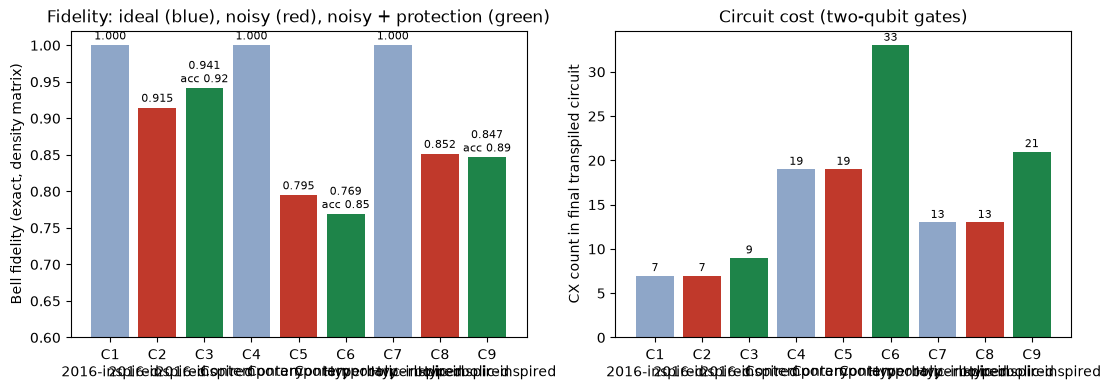

In [10]:
labels = [f"C{r['case']}\n{r['model'].split()[0]}" for r in rows]
fids = [r["fidelity"] for r in rows]
cxs = [r["cx"] for r in rows]
colors = ["#8ea6c8" if r["condition"] == "Ideal baseline" else
          "#c0392b" if r["condition"] == "Noisy baseline" else "#1e8449" for r in rows]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained")
ax1.bar(labels, fids, color=colors)
ax1.set_ylim(0.6, 1.02); ax1.set_ylabel("Bell fidelity (exact, density matrix)")
ax1.set_title("Fidelity: ideal (blue), noisy (red), noisy + protection (green)")
for i, (f, r) in enumerate(zip(fids, rows)):
    note = f"{f:.3f}" + (f"\nacc {r['acceptance']:.2f}" if r["condition"] == "Noisy + protection" else "")
    ax1.text(i, f + 0.008, note, ha="center", fontsize=8)
ax2.bar(labels, cxs, color=colors)
ax2.set_ylabel("CX count in final transpiled circuit")
ax2.set_title("Circuit cost (two-qubit gates)")
for i, c in enumerate(cxs):
    ax2.text(i, c + 0.5, str(c), ha="center", fontsize=8)
plt.show()

## 7. Finite-shot cross-check with uncertainties

The headline fidelities above are exact for the stated noise model. To report the uncertainty a measurement-based experiment would carry, each case is repeated here in the form of the checkpoint example notebook: for each basis ($ZZ$ directly, $XX$ after H on both ports, $YY$ after S$^\dagger$ then H on both ports), the ports are measured, and for protected cases the ancilla is measured in the same circuit and only ancilla-$0$ shots are kept. With $N$ kept shots per basis, $\mathrm{Var}(\langle BB\rangle) \approx (1 - \langle BB\rangle^2)/N$ and $\sigma_F = \frac{1}{4}\sqrt{\sum_B \mathrm{Var}(\langle BB\rangle)}$. Shots: 8192 per basis, fixed seed. The shot estimates should agree with the exact values within about $2\sigma_F$.

In [11]:
SHOTS = 8192
SEED = 1234
shot_sim_ideal = AerSimulator()
shot_sim_noisy = AerSimulator(noise_model=noise_model)

def shot_fidelity(circuit, ports, ancilla, noisy):
    n = circuit.num_qubits
    sim = shot_sim_noisy if noisy else shot_sim_ideal
    corrs, ns = {}, {}
    for basis in ("XX", "YY", "ZZ"):
        qc = QuantumCircuit(n, 3 if ancilla is not None else 2)
        qc.compose(circuit, qubits=list(range(n)), inplace=True)
        if basis == "XX":
            qc.h(list(ports))
        elif basis == "YY":
            qc.sdg(list(ports)); qc.h(list(ports))
        qc.measure(ports[0], 0); qc.measure(ports[1], 1)
        if ancilla is not None:
            qc.measure(ancilla, 2)
        counts = sim.run(qc, shots=SHOTS, seed_simulator=SEED).result().get_counts()
        kept, total_corr = 0, 0
        for bitstring, c in counts.items():
            if ancilla is not None and bitstring[0] != "0":  # clbit 2 is the leftmost character
                continue
            a, b = bitstring[-1], bitstring[-2]  # clbit 0 = port A (rightmost), clbit 1 = port B
            kept += c
            total_corr += c if a == b else -c
        corrs[basis] = total_corr / kept
        ns[basis] = kept
    f = (1 + corrs["XX"] - corrs["YY"] + corrs["ZZ"]) / 4
    var = sum((1 - corrs[b] ** 2) / ns[b] for b in corrs)
    return f, math.sqrt(var) / 4, min(ns.values())

print(f"{'Case':<5}{'Shot fidelity':>16}{'Exact':>9}{'Diff / sigma':>14}")
for r in rows:
    name = r["model"]
    circ = protected[name]["circuit"] if r["condition"] == "Noisy + protection" else unprotected[name]["circuit"]
    anc = models[name]["ancilla"] if r["condition"] == "Noisy + protection" else None
    f_shot, se, nmin = shot_fidelity(circ, r["ports"], anc, noisy=(r["condition"] != "Ideal baseline"))
    pull = (f_shot - r["fidelity"]) / se if se > 0 else 0.0
    print(f"{r['case']:<5}{f_shot:.4f} +/- {se:.4f}{r['fidelity']:>9.4f}{pull:>14.2f}   (min kept shots/basis {nmin})")

Case    Shot fidelity    Exact  Diff / sigma
1    1.0000 +/- 0.0000   1.0000          0.00   (min kept shots/basis 8192)
2    0.9136 +/- 0.0022   0.9147         -0.46   (min kept shots/basis 8192)
3    0.9401 +/- 0.0020   0.9414         -0.68   (min kept shots/basis 7487)
4    1.0000 +/- 0.0000   1.0000          0.00   (min kept shots/basis 8192)


5    0.7943 +/- 0.0033   0.7949         -0.19   (min kept shots/basis 8192)
6    0.7637 +/- 0.0038   0.7692         -1.45   (min kept shots/basis 6886)


7    1.0000 +/- 0.0000   1.0000          0.00   (min kept shots/basis 8192)
8    0.8477 +/- 0.0029   0.8515         -1.35   (min kept shots/basis 8192)
9    0.8417 +/- 0.0031   0.8467         -1.62   (min kept shots/basis 7333)


## 8. Scientific interpretation

**Routing cost, not processor size, sets the noisy baseline.** The three port pairs sit at graph distances 2, 4, and 3 hops (2016-inspired, contemporary, hyperbolic). With the starter compilation, outbound SWAPs are hops minus 1, and the final CX count is $1 + 6s$: 7, 19, and 13. Noisy fidelity follows that ordering exactly: 0.915, 0.795, 0.852. The 13-qubit hyperbolic model therefore outperforms the 9-qubit contemporary model on this task, not because of its size or its extra cycles in the abstract, but because the specific designated ports happen to be one hop closer, which removes 6 CX gates and their noise. Any architecture comparison that reported only qubit counts would get this ordering wrong; the operative variable is the routed two-qubit gate count between the designated ports. In all three models the transverse correlations $\langle XX\rangle$ and $\langle YY\rangle$ decay faster than $\langle ZZ\rangle$ (for example 0.681 vs 0.817 on the contemporary model), so the fidelity loss is dominated by loss of phase coherence, not by classical bit disagreement. A $ZZ$-only check would have overstated the pair quality on every model.

**The parity check pays exactly when it is free of routing.** On the 2016-inspired model, qubit 3 is adjacent to both ports and already lies on the delivery path: the check costs 2 CX and 0 SWAPs, conditional fidelity improves from 0.915 to 0.941, and 91.7% of shots survive. On the contemporary model the cheapest check segment costs 14 CX (2 outbound SWAPs plus return), and on the hyperbolic model 8 CX (1 outbound SWAP plus return). In both cases conditional fidelity ends below the unprotected noisy baseline (0.769 vs 0.795; 0.847 vs 0.852), even though 15.2% and 10.8% of the data were discarded to obtain it. Comparing the protected unconditional fidelity with the conditional value shows the check does detect real errors (postselection recovers part of the loss its own gates cause), but the detected class, odd-weight bit flips before the check, is only part of the depolarizing noise, and the check segment injects fresh noise of every class, including noise on the return SWAPs that occurs after the parity has been copied and is undetectable in principle within this scheme. The hyperbolic case is close to break-even (a 0.005 deficit at 89.2% yield), which is consistent with its lower check cost; the contemporary case, with the most expensive check, shows the largest deficit.

**Yield is part of the result.** Postselection is not free data processing: at fixed shot budget the contemporary protected case keeps about 0.85 of shots and still loses fidelity, so its effective cost per accepted, higher-quality pair is worse on both axes. Reporting conditional fidelity without the acceptance fraction would have hidden this.

**Limitations.**

1. The noise model is a single synthetic channel: two-qubit depolarizing noise at 0.02 after each CX, ideal H gates, no readout error, relaxation, dephasing during idle time, or crosstalk. Real devices would change absolute fidelities and could change the protection balance (for example, readout error on the ancilla would add false rejects).
2. Compilation uses the starter notebook's `basic` router at optimization level 0 for every case, deliberately, so that all models share one compilation policy. A stronger router or optimization could reduce CX counts on all models; the conclusions are about this common benchmark configuration and about the cost mechanism, not a universal ranking of the three architectures.
3. One port pair, one Bell state, and one protection strategy were tested, as the prompt requires. The parity check detects only odd-weight bit-flip errors and performs no correction; a fuller stabilizer scheme, or a check against both $ZZ$ and $XX$ parities, could behave differently at higher overhead.
4. Headline fidelities are exact density-matrix values for the stated model, so they have no sampling error; the finite-shot cross-check in Section 7 quantifies the uncertainty of a shot-based repetition and agrees with the exact values.
5. These are finite, small graphs. The hyperbolic model's advantage here is a statement about these two ports on this 13-qubit graph, not evidence of a general hyperbolic-architecture advantage.

## 9. Recommendation for future cloud systems

**Hardware design choice: place a dedicated parity-check ancilla adjacent to both qubits of each designated entanglement port pair, on a shortest port-to-port path, so that a $ZZ$ parity check on a delivered pair costs exactly 2 CX and 0 SWAPs.**

Evidence from this benchmark: the 2016-inspired model is the only one whose graph already contains such a qubit (qubit 3, adjacent to ports 0 and 4), and it is the only model where protection produced a net gain, +0.027 fidelity at 91.7% yield for 2 extra CX. Every routed check lost fidelity despite discarding 11 to 15% of shots, and the loss grew with the check segment's CX count (8 CX: -0.005; 14 CX: -0.026). Error detection at the port is therefore a connectivity feature, not only a circuit feature: if the check ancilla is not built into the port geometry, the routing needed to reach it consumes the entire benefit under gate noise at the 0.02 level. Until such ancillas exist, the interim software mitigation supported by the ancilla scan in Section 5 is to select the check ancilla by compiled check-segment cost (fewest SWAPs, then shortest port distances), which on the hyperbolic model halves the protection deficit relative to a central-ancilla choice (segment 8 CX, deficit 0.005, vs segment 14 CX, deficit 0.052 for ancilla 6; see Appendix A data in the scan output and sensitivity run).

## Appendix A. Noise-strength sensitivity (optional study, separate from the common benchmark)

The common benchmark above uses $p = 0.02$ throughout. As a separate sensitivity check, the noisy and protected cases are recomputed at $p = 0.01$ and $p = 0.05$ with identical circuits. The ordering of models and the sign of the protection effect are unchanged at both strengths: protection gains only on the 2016-inspired model, and the deficit grows with check-segment cost. Absolute fidelities scale roughly linearly with $p \times$ CX count in this range.

In [12]:
for p in (0.01, 0.05):
    nm = NoiseModel()
    nm.add_all_qubit_quantum_error(depolarizing_error(p, 2), ["cx"])
    sim_p = AerSimulator(method="density_matrix", noise_model=nm)
    print(f"--- p = {p} ---")
    for name, m in models.items():
        _, f_base = port_fidelity_from_dm(run_dm(unprotected[name]["circuit"], m["ports"], sim_p))
        dm3 = run_dm(protected[name]["circuit"], (m["ports"][0], m["ports"][1], m["ancilla"]), sim_p)
        _, f_cond, p_acc = conditional_metrics(dm3)
        print(f"{name}: noisy baseline F = {f_base:.4f} | protected conditional F = {f_cond:.4f} "
              f"(change {f_cond - f_base:+.4f}), acceptance {p_acc:.4f}")

--- p = 0.01 ---


2016-inspired reference: noisy baseline F = 0.9562 | protected conditional F = 0.9710 (change +0.0148), acceptance 0.9568
Contemporary IBM-style: noisy baseline F = 0.8892 | protected conditional F = 0.8741 (change -0.0151), acceptance 0.9173
Hyperbolic-inspired model: noisy baseline F = 0.9218 | protected conditional F = 0.9193 (change -0.0025), acceptance 0.9432
--- p = 0.05 ---
2016-inspired reference: noisy baseline F = 0.8028 | protected conditional F = 0.8511 (change +0.0483), acceptance 0.8151
Contemporary IBM-style: noisy baseline F = 0.5884 | protected conditional F = 0.5527 (change -0.0357), acceptance 0.6986
Hyperbolic-inspired model: noisy baseline F = 0.6813 | protected conditional F = 0.6719 (change -0.0094), acceptance 0.7702


## Appendix B. Reproducibility

- Inputs: `Hackathon.zip` from the UCF Qiskit Fall Fest site (organizer page by Neer Patel), re-downloaded 2026-11-17; processor definitions and compilation method taken from its `ideal_and_noisy_example.ipynb` and the quanTA prompt deck PDF in the same zip.
- Environment: Qiskit 2.6.2, Qiskit Aer 0.18.2, Python 3.12 (dedicated venv). Density-matrix runs use `shots=1` with `save_density_matrix`, which is exact state evolution, not sampling. Shot cross-check: 8192 shots per basis, `seed_simulator=1234`.
- Assertions in the notebook verify: every CX in every compiled circuit lies on the model's coupling graph; ideal unprotected fidelity is 1 on all models; ideal protected conditional fidelity and acceptance are both 1.
- All nine core cases use the single common noise model ($p=0.02$ after each CX). Appendix A is an optional sensitivity study and is not part of the core comparison.